# Evaluasi Kinerja Model Generative Aspect-Based Sentiment Analysis (GABSA)
### Tugas Akhir / Skripsi: Ekstraksi Opini Pasien Rumah Sakit Berbasis Large Language Model (Qwen2.5)

---

## 📌 Latar Belakang & Tujuan Evaluasi

Tugas utama model generatif pada penelitian ini (**Task A: GABSA**) adalah mentransformasi teks ulasan pasien rumah sakit yang tidak terstruktur dari Google Maps menjadi representasi informasi opini terstruktur berupa triplet JSON:
$$\text{Triplet} = \left[ \text{Aspek Layanan}, \; \text{Polaritas Sentimen}, \; \text{Bukti Teks (Evidence Span)} \right]$$

Pengujian performa model dilakukan pada kumpulan data uji acuan (*test set*) yang terdiri dari **$1.181$ ulasan**. Model yang dievaluasi dan dibandingkan mencakup tiga skenario:
1. **Base Model (Zero-Shot):** Model dasar `Qwen2.5-7B-Instruct` dengan instruksi sistem tanpa contoh acuan.
2. **Base Model (Few-Shot):** Model dasar `Qwen2.5-7B-Instruct` dengan instruksi disertai 3 contoh pasangan input-output statis pada *prompt*.
3. **Fine-Tuned Model (QLoRA):** Model `Qwen2.5-7B-Instruct` yang telah diadaptasi menggunakan teknik *Parameter-Efficient Fine-Tuning* (PEFT) melalui *Quantized Low-Rank Adaptation* (QLoRA) dengan konfigurasi $r=16, \alpha=32$.

---

## 📐 Tiga Dimensi Pengukuran & Metrik Pelengkap
Kinerja model diukur secara komprehensif pada tiga dimensi klasifikasi serta dua metrik kualitas keluaran teks:
1. **Dimensi 1: Aspect Extraction:** Kemampuan model mengidentifikasi 7 kategori aspek kualitas pelayanan rumah sakit.
2. **Dimensi 2: Sentiment Extraction:** Kemampuan model menentukan polaritas sentimen (positif, netral, negatif).
3. **Dimensi 3: Pair Extraction (Aspek–Sentimen):** Kemampuan model mengekstraksi pasangan aspek dan sentimen secara simultan ($21$ kombinasi).
4. **Token-Level Evidence Overlap F1:** Kesesuaian potongan teks bukti (*evidence span*) antara prediksi model dan anotasi acuan manusia.
5. **JSON Schema Compliance Rate:** Tingkat kepatuhan sintaksis keluaran model terhadap format JSON yang valid.


---
## 1. Penjelasan Detail Metrik Evaluasi Kinerja

### 1.1 Precision, Recall, dan F1-Score
Pada ekstraksi multi-label, evaluasi dihitung dari perbandingan elemen himpunan prediksi ($S_{\text{pred}}$) terhadap himpunan acuan ground truth ($S_{\text{gt}}$):

$$\text{True Positive } (TP) = |S_{\text{pred}} \cap S_{\text{gt}}|, \quad \text{False Positive } (FP) = |S_{\text{pred}} \setminus S_{\text{gt}}|, \quad \text{False Negative } (FN) = |S_{\text{gt}} \setminus S_{\text{pred}}|$$

Dari ketiga besaran kontingensi tersebut, dirumuskan:
- **Precision ($P$):** Mengukur ketepatan prediksi model (mencegah halusinasi atau pelabelan berlebih).
  $$P = \frac{TP}{TP + FP}$$
- **Recall ($R$):** Mengukur kelengkapan deteksi model (mencegah informasi relevan terlewat).
  $$R = \frac{TP}{TP + FN}$$
- **F1-Score ($F_1$):** Rata-rata harmonik antara presisi dan recall untuk memberikan gambaran performa yang seimbang.
  $$F_1 = 2 \cdot \frac{P \cdot R}{P + R} = \frac{2TP}{2TP + FP + FN}$$

### 1.2 Agregasi Makro (*Macro-Averaging*)
Evaluasi per kategori menggunakan rata-rata makro:
$$\text{Macro } F_1 = \frac{1}{K} \sum_{k=1}^{K} F_1^{(k)}$$
Pendekatan ini memberikan bobot yang setara pada setiap kategori tanpa memandang jumlah sampel (*support*), sehingga performa pada aspek minoritas (seperti `parkir_akses`) dinilai sama pentingnya dengan aspek mayoritas (`pelayanan`).

### 1.3 Token-Level Evidence Overlap F1
Potongan bukti teks (*evidence span*) tidak dapat dinilai dengan pencocokan string eksak karena variasi batas kata leksikal. Kesesuaian span diukur melalui tumpang tindih token (*token overlap*):
$$P_{\text{token}} = \frac{|T_{\text{ref}} \cap T_{\text{pred}}|}{|T_{\text{pred}}|}, \qquad R_{\text{token}} = \frac{|T_{\text{ref}} \cap T_{\text{pred}}|}{|T_{\text{ref}}|}$$
$$F_{1,\text{token}} = \frac{2 \cdot P_{\text{token}} \cdot R_{\text{token}}}{P_{\text{token}} + R_{\text{token}}}$$

### 1.4 Kepatuhan Format JSON (*JSON Schema Compliance*)
- **Strict JSON Rate:** Persentase ulasan di mana keluaran model dapat langsung diparsing via `json.loads()` murni tanpa teks pengantar atau blok markdown.
- **Total Valid JSON Rate:** Persentase keluaran yang memuat struktur data JSON valid (termasuk yang diekstrak dengan toleransi regex).
- **Invalid Format Rate:** Persentase kegagalan sintaksis (misalnya kurung kurawal tidak tertutup).


In [1]:
import json
import re
import os
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

# Konfigurasi gaya visualisasi matplotlib
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8

# Resolusi path file dataset (fleksibel jika dijalankan dari 'notebook/' atau root direktori)
def resolve_path(rel_path):
    p = Path(rel_path)
    if p.exists():
        return str(p)
    p_parent = Path("..") / rel_path
    if p_parent.exists():
        return str(p_parent)
    return rel_path

PATH_TEST_GT = resolve_path("dataset/data_split/gabsa_test.jsonl")
PATH_PRED_FT = resolve_path("dataset/inference_result/gabsa_predictions_finetune.jsonl")
PATH_PRED_ZERO = resolve_path("dataset/inference_result/gabsa_predictions_base_zero.jsonl")
PATH_PRED_FEW = resolve_path("dataset/inference_result/gabsa_predictions_base_few.jsonl")

# Taksonomi aspek dan sentimen
ASPECTS = [
    'kebersihan',
    'pelayanan',
    'waktu_tunggu',
    'parkir_akses',
    'tenaga_medis',
    'fasilitas',
    'administrasi'
]

SENTS = ['positif', 'netral', 'negatif']

PAIRS = [f"{a}__{s}" for a in ASPECTS for s in SENTS]

print("=" * 75)
print("SETUP DAN RESOLUSI BERKAS EVALUASI")
print("=" * 75)
print(f"Ground Truth Test Set : {PATH_TEST_GT}")
print(f"Prediksi Fine-Tuned   : {PATH_PRED_FT}")
print(f"Prediksi Base Zero    : {PATH_PRED_ZERO}")
print(f"Prediksi Base Few     : {PATH_PRED_FEW}")
print(f"Jumlah Kategori Aspek : {len(ASPECTS)} -> {ASPECTS}")
print(f"Jumlah Kelas Sentimen : {len(SENTS)} -> {SENTS}")
print(f"Jumlah Pasangan Pair  : {len(PAIRS)} kombinasi")
print("=" * 75)


SETUP DAN RESOLUSI BERKAS EVALUASI
Ground Truth Test Set : dataset/data_split/gabsa_test.jsonl
Prediksi Fine-Tuned   : dataset/inference_result/gabsa_predictions_finetune.jsonl
Prediksi Base Zero    : dataset/inference_result/gabsa_predictions_base_zero.jsonl
Prediksi Base Few     : dataset/inference_result/gabsa_predictions_base_few.jsonl
Jumlah Kategori Aspek : 7 -> ['kebersihan', 'pelayanan', 'waktu_tunggu', 'parkir_akses', 'tenaga_medis', 'fasilitas', 'administrasi']
Jumlah Kelas Sentimen : 3 -> ['positif', 'netral', 'negatif']
Jumlah Pasangan Pair  : 21 kombinasi


---
## 2. Fungsi Parser JSON dan Komputasi Metrik Evaluasi

Pada sel berikut didefinisikan:
1. `get_token_f1(ref_str, pred_str)`: Menghitung tumpang tindih token bukti teks (*evidence overlap*).
2. `safe_parse_json(content)`: Memvalidasi keluaran model secara bertingkat (*Strict Parsing* dan *Lenient Regex Fallback*) serta mendeteksi kegagalan format.
3. `load_jsonl(filepath)`: Membaca berkas JSONL ke dalam struktur data list Python.


In [2]:
def get_token_f1(ref_str, pred_str):
    """Menghitung token-level F1-Score antara string teks bukti referensi dan prediksi."""
    if not isinstance(ref_str, str): ref_str = ""
    if not isinstance(pred_str, str): pred_str = ""
    
    ref_tokens = re.sub(r'[^\w\s]', '', ref_str.lower()).split()
    pred_tokens = re.sub(r'[^\w\s]', '', pred_str.lower()).split()
    
    if not ref_tokens and not pred_tokens:
        return 1.0
    if not ref_tokens or not pred_tokens:
        return 0.0
        
    ref_cnt = Counter(ref_tokens)
    pred_cnt = Counter(pred_tokens)
    overlap = sum((ref_cnt & pred_cnt).values())
    
    p = overlap / len(pred_tokens)
    r = overlap / len(ref_tokens)
    if p + r == 0:
        return 0.0
    return 2 * p * r / (p + r)

def safe_parse_json(content):
    """Memvalidasi dan mem-parsing JSON keluaran model secara strict dan lenient."""
    if not isinstance(content, str) or not content.strip():
        return [], False, False
        
    # 1. Strict Parsing via json.loads
    try:
        data = json.loads(content.strip())
        is_strict = False
        labels = []
        if isinstance(data, dict):
            if "labels" in data and isinstance(data["labels"], list):
                labels = data["labels"]
                is_strict = True
            elif "output" in data and isinstance(data["output"], list):
                labels = data["output"]
                is_strict = True
            elif "aspect" in data and "sentiment" in data:
                labels = [data]
                is_strict = True
        elif isinstance(data, list):
            labels = data
            is_strict = True
            
        if is_strict:
            for item in labels:
                if not isinstance(item, dict) or "aspect" not in item or "sentiment" not in item:
                    is_strict = False
                    break
        if is_strict:
            return labels, True, True
    except:
        pass

    # 2. Lenient Parsing via Regex Fallback
    try:
        match = re.search(r'\{.*\}', content.strip(), re.DOTALL)
        if match:
            data = json.loads(match.group())
            labels = data.get("labels", data.get("output", []))
            if isinstance(labels, list):
                valid_lenient = True
                for item in labels:
                    if not isinstance(item, dict) or "aspect" not in item or "sentiment" not in item:
                        valid_lenient = False
                        break
                if valid_lenient:
                    return labels, False, True
    except:
        pass
        
    try:
        match = re.search(r'\[.*\]', content.strip(), re.DOTALL)
        if match:
            data = json.loads(match.group())
            if isinstance(data, list):
                valid_lenient = True
                for item in data:
                    if not isinstance(item, dict) or "aspect" not in item or "sentiment" not in item:
                        valid_lenient = False
                        break
                if valid_lenient:
                    return data, False, True
    except:
        pass
        
    return [], False, False

def load_jsonl(filepath):
    records = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            if line.strip():
                records.append(json.loads(line.strip()))
    return records

print("Fungsi parser JSON dan token-level overlap F1 siap digunakan.")


Fungsi parser JSON dan token-level overlap F1 siap digunakan.


---
## 3. Logika Komputasi Evaluasi Multi-Label & Matriks Kontingensi

Fungsi `evaluate_gabsa_comprehensive` di bawah ini menghitung:
1. **Metrik Global Task A:** Precision, Recall, F1-Score untuk Dimensi Aspek, Sentimen, dan Pasangan Aspek-Sentimen.
2. **Matriks Kontingensi Biner ($2 \times 2$):** $TP, FP, FN, TN$ untuk tiap-tiap dari 7 kategori aspek.
3. **Matriks Kontingensi Biner ($2 \times 2$):** $TP, FP, FN, TN$ untuk tiap-tiap dari 3 kelas sentimen.
4. **Matriks Kontingensi Biner ($2 \times 2$):** $TP, FP, FN, TN$ untuk tiap-tiap dari 21 pasangan aspek-sentimen.
5. **Matriks Kontingensi Multikelas ($3 \times 3$):** Ground truth sentimen vs predicted sentimen pada aspek yang sama-sama terdeteksi.
6. **Token-Level Evidence Overlap:** Rata-rata skor F1 token evidence dan daftar skor per ulasan.
7. **Statistik Kepatuhan JSON:** Jumlah dan persentase *strict*, *lenient*, serta *invalid*.


In [3]:
def evaluate_gabsa_comprehensive(records, aspect_list, sent_list):
    total_samples = len(records)
    
    strict_count = 0
    valid_count = 0
    invalid_count = 0
    
    # Global counts
    tp_a, fp_a, fn_a = 0, 0, 0
    tp_s, fp_s, fn_s = 0, 0, 0
    tp_p, fp_p, fn_p = 0, 0, 0
    
    # Binary contingency per aspect: {aspect: {tp, fp, fn, tn}}
    cm_aspects = {a: {"tp": 0, "fp": 0, "fn": 0, "tn": 0} for a in aspect_list}
    
    # Binary contingency per sentiment: {sentiment: {tp, fp, fn, tn}}
    cm_sents_binary = {s: {"tp": 0, "fp": 0, "fn": 0, "tn": 0} for s in sent_list}
    
    # Multiclass 3x3 contingency matrix: {gt_sent: {pred_sent: count}}
    cm_sents_3x3 = {sg: {sp: 0 for sp in sent_list} for sg in sent_list}
    
    # Binary contingency per pair: {(aspect, sentiment): {tp, fp, fn, tn}}
    pairs_list = [(a, s) for a in aspect_list for s in sent_list]
    cm_pairs = {p: {"tp": 0, "fp": 0, "fn": 0, "tn": 0} for p in pairs_list}
    
    evidence_f1s_global = []
    
    for row in records:
        # Ambil label acuan ground truth
        gt_raw = row.get("reference_labels", row.get("labels", []))
        
        # Ambil prediksi model
        if "predicted_labels" in row:
            pred_raw = row["predicted_labels"]
            is_strict = True
            is_valid = True
        elif "prediction_raw" in row:
            pred_raw, is_strict, is_valid = safe_parse_json(row["prediction_raw"])
        else:
            pred_raw, is_strict, is_valid = [], False, False
            
        if is_strict:
            strict_count += 1
        if is_valid:
            valid_count += 1
        else:
            invalid_count += 1
            
        if isinstance(pred_raw, dict) and "labels" in pred_raw:
            pred_raw = pred_raw["labels"]
        if not isinstance(pred_raw, list):
            pred_raw = []
            
        # Filter aspek yang valid
        gt_aspects = {l["aspect"].strip().lower() for l in gt_raw if isinstance(l, dict) and "aspect" in l and l["aspect"].strip().lower() in aspect_list}
        pred_aspects = {l["aspect"].strip().lower() for l in pred_raw if isinstance(l, dict) and "aspect" in l and l["aspect"].strip().lower() in aspect_list}
        
        gt_sents = {l["sentiment"].strip().lower() for l in gt_raw if isinstance(l, dict) and "sentiment" in l and l.get("aspect", "").strip().lower() in aspect_list and l["sentiment"].strip().lower() in sent_list}
        pred_sents = {l["sentiment"].strip().lower() for l in pred_raw if isinstance(l, dict) and "sentiment" in l and l.get("aspect", "").strip().lower() in aspect_list and l["sentiment"].strip().lower() in sent_list}
        
        gt_pairs = {(l["aspect"].strip().lower(), l["sentiment"].strip().lower()) for l in gt_raw if isinstance(l, dict) and "aspect" in l and "sentiment" in l and l["aspect"].strip().lower() in aspect_list and l["sentiment"].strip().lower() in sent_list}
        pred_pairs = {(l["aspect"].strip().lower(), l["sentiment"].strip().lower()) for l in pred_raw if isinstance(l, dict) and "aspect" in l and "sentiment" in l and l["aspect"].strip().lower() in aspect_list and l["sentiment"].strip().lower() in sent_list}
        
        # 1. Global Counts
        tp_a += len(gt_aspects & pred_aspects)
        fp_a += len(pred_aspects - gt_aspects)
        fn_a += len(gt_aspects - pred_aspects)
        
        tp_s += len(gt_sents & pred_sents)
        fp_s += len(pred_sents - gt_sents)
        fn_s += len(gt_sents - pred_sents)
        
        tp_p += len(gt_pairs & pred_pairs)
        fp_p += len(pred_pairs - gt_pairs)
        fn_p += len(gt_pairs - pred_pairs)
        
        # 2. Per-Aspect 2x2 Contingency
        for a in aspect_list:
            in_gt = a in gt_aspects
            in_pred = a in pred_aspects
            if in_gt and in_pred:
                cm_aspects[a]["tp"] += 1
            elif in_pred and not in_gt:
                cm_aspects[a]["fp"] += 1
            elif in_gt and not in_pred:
                cm_aspects[a]["fn"] += 1
            else:
                cm_aspects[a]["tn"] += 1
                
        # 3. Per-Sentiment Binary 2x2 Contingency
        for s in sent_list:
            in_gt = s in gt_sents
            in_pred = s in pred_sents
            if in_gt and in_pred:
                cm_sents_binary[s]["tp"] += 1
            elif in_pred and not in_gt:
                cm_sents_binary[s]["fp"] += 1
            elif in_gt and not in_pred:
                cm_sents_binary[s]["fn"] += 1
            else:
                cm_sents_binary[s]["tn"] += 1
                
        # 4. Sentiment Multiclass 3x3 Contingency (pada aspek yang sama-sama terdeteksi)
        for a_matched in (gt_aspects & pred_aspects):
            sg_set = {p[1] for p in gt_pairs if p[0] == a_matched}
            sp_set = {p[1] for p in pred_pairs if p[0] == a_matched}
            for sg in sg_set:
                for sp in sp_set:
                    if sg in sent_list and sp in sent_list:
                        cm_sents_3x3[sg][sp] += 1
                        
        # 5. Per-Pair 2x2 Contingency
        for p in pairs_list:
            in_gt = p in gt_pairs
            in_pred = p in pred_pairs
            if in_gt and in_pred:
                cm_pairs[p]["tp"] += 1
            elif in_pred and not in_gt:
                cm_pairs[p]["fp"] += 1
            elif in_gt and not in_pred:
                cm_pairs[p]["fn"] += 1
            else:
                cm_pairs[p]["tn"] += 1
                
        # 6. Global Token Evidence Overlap
        gt_all_ev = " ".join([l.get("evidence", "") for l in gt_raw if isinstance(l, dict) and l.get("evidence")])
        pred_all_ev = " ".join([l.get("evidence", "") for l in pred_raw if isinstance(l, dict) and l.get("evidence")])
        evidence_f1s_global.append(get_token_f1(gt_all_ev, pred_all_ev))
        
    def calc_prf(tp, fp, fn):
        p = tp / (tp + fp) if tp + fp > 0 else 0.0
        r = tp / (tp + fn) if tp + fn > 0 else 0.0
        f = 2 * p * r / (p + r) if p + r > 0 else 0.0
        return p, r, f
        
    p_a, r_a, f_a = calc_prf(tp_a, fp_a, fn_a)
    p_s, r_s, f_s = calc_prf(tp_s, fp_s, fn_s)
    p_p, r_p, f_p = calc_prf(tp_p, fp_p, fn_p)
    
    # Detail metrik per aspek
    aspect_metrics = {}
    for a in aspect_list:
        p_val, r_val, f_val = calc_prf(cm_aspects[a]["tp"], cm_aspects[a]["fp"], cm_aspects[a]["fn"])
        aspect_metrics[a] = {
            "precision": p_val,
            "recall": r_val,
            "f1": f_val,
            "tp": cm_aspects[a]["tp"],
            "fp": cm_aspects[a]["fp"],
            "fn": cm_aspects[a]["fn"],
            "tn": cm_aspects[a]["tn"],
            "support": cm_aspects[a]["tp"] + cm_aspects[a]["fn"]
        }
        
    # Detail metrik per pair
    pair_metrics = {}
    for p in pairs_list:
        p_val, r_val, f_val = calc_prf(cm_pairs[p]["tp"], cm_pairs[p]["fp"], cm_pairs[p]["fn"])
        pair_metrics[p] = {
            "precision": p_val,
            "recall": r_val,
            "f1": f_val,
            "tp": cm_pairs[p]["tp"],
            "fp": cm_pairs[p]["fp"],
            "fn": cm_pairs[p]["fn"],
            "tn": cm_pairs[p]["tn"],
            "support": cm_pairs[p]["tp"] + cm_pairs[p]["fn"]
        }
        
    return {
        "total_samples": total_samples,
        "aspect_p": p_a, "aspect_r": r_a, "aspect_f1": f_a,
        "sentiment_p": p_s, "sentiment_r": r_s, "sentiment_f1": f_s,
        "pair_p": p_p, "pair_r": r_p, "pair_f1": f_p,
        "aspect_metrics": aspect_metrics,
        "pair_metrics": pair_metrics,
        "cm_aspects": cm_aspects,
        "cm_sents_binary": cm_sents_binary,
        "cm_sents_3x3": cm_sents_3x3,
        "cm_pairs": cm_pairs,
        "evidence_overlap_mean": float(np.mean(evidence_f1s_global)),
        "evidence_overlap_list": evidence_f1s_global,
        "strict_rate": (strict_count / total_samples) * 100.0,
        "valid_rate": (valid_count / total_samples) * 100.0,
        "invalid_rate": (invalid_count / total_samples) * 100.0,
    }

print("Fungsi komputasi evaluasi komprehensif GABSA siap digunakan.")


Fungsi komputasi evaluasi komprehensif GABSA siap digunakan.


---
## 4. Evaluasi Model Utama: Fine-Tuned QLoRA Qwen2.5

Pada tahap ini, kita memuat hasil prediksi model utama hasil adaptasi QLoRA (`gabsa_predictions_finetune.jsonl`) dan menghitung seluruh indikator performa untuk ketiga dimensi evaluasi.


In [4]:
records_ft = load_jsonl(PATH_PRED_FT)
res_ft = evaluate_gabsa_comprehensive(records_ft, ASPECTS, SENTS)

print("=" * 75)
print("HASIL EVALUASI MODEL UTAMA (FINE-TUNED QLoRA QWEN2.5)")
print("=" * 75)
print(f"Total Sampel Data Uji : {res_ft['total_samples']} ulasan")
print(f"Kepatuhan JSON Strict : {res_ft['strict_rate']:.2f}%")
print(f"Kepatuhan JSON Total  : {res_ft['valid_rate']:.2f}%")
print(f"Kegagalan Format      : {res_ft['invalid_rate']:.2f}%")
print()

print("HASIL METRIK UTAMA PER DIMENSI PENGUKURAN:")
print(f"  1. Aspect Extraction    : Precision={res_ft['aspect_p']*100:.2f}%, Recall={res_ft['aspect_r']*100:.2f}%, F1={res_ft['aspect_f1']*100:.2f}%")
print(f"  2. Sentiment Extraction : Precision={res_ft['sentiment_p']*100:.2f}%, Recall={res_ft['sentiment_r']*100:.2f}%, F1={res_ft['sentiment_f1']*100:.2f}%")
print(f"  3. Pair Extraction      : Precision={res_ft['pair_p']*100:.2f}%, Recall={res_ft['pair_r']*100:.2f}%, F1={res_ft['pair_f1']*100:.2f}%")
print(f"  4. Evidence Overlap F1  : {res_ft['evidence_overlap_mean']*100:.2f}%")
print("-" * 75)

print()
print("PERFORMA RINCI PER KATEGORI ASPEK LAYANAN (DIMENSI 1):")
print(f"{'Kategori Aspek':<16} | {'Precision':<10} | {'Recall':<10} | {'F1-Score':<10} | {'TP':<5} {'FP':<5} {'FN':<5} {'TN':<5} | {'Support':<7}")
print("-" * 80)
total_support = 0
for a in ASPECTS:
    m = res_ft["aspect_metrics"][a]
    total_support += m["support"]
    print(f"{a:<16} | {m['precision']*100:>7.2f}%   | {m['recall']*100:>7.2f}%   | {m['f1']*100:>7.2f}%   | {m['tp']:<5} {m['fp']:<5} {m['fn']:<5} {m['tn']:<5} | {m['support']:<7}")

macro_p = float(np.mean([res_ft["aspect_metrics"][a]["precision"] for a in ASPECTS]))
macro_r = float(np.mean([res_ft["aspect_metrics"][a]["recall"] for a in ASPECTS]))
macro_f = float(np.mean([res_ft["aspect_metrics"][a]["f1"] for a in ASPECTS]))
print("-" * 80)
print(f"{'Rata-rata Makro':<16} | {macro_p*100:>7.2f}%   | {macro_r*100:>7.2f}%   | {macro_f*100:>7.2f}%   | {'-':<5} {'-':<5} {'-':<5} {'-':<5} | {total_support:<7}")
print("=" * 80)


HASIL EVALUASI MODEL UTAMA (FINE-TUNED QLoRA QWEN2.5)
Total Sampel Data Uji : 1181 ulasan
Kepatuhan JSON Strict : 100.00%
Kepatuhan JSON Total  : 100.00%
Kegagalan Format      : 0.00%

HASIL METRIK UTAMA PER DIMENSI PENGUKURAN:
  1. Aspect Extraction    : Precision=79.28%, Recall=79.37%, F1=79.32%
  2. Sentiment Extraction : Precision=96.60%, Recall=95.29%, F1=95.94%
  3. Pair Extraction      : Precision=77.23%, Recall=76.92%, F1=77.07%
  4. Evidence Overlap F1  : 76.75%
---------------------------------------------------------------------------

PERFORMA RINCI PER KATEGORI ASPEK LAYANAN (DIMENSI 1):
Kategori Aspek   | Precision  | Recall     | F1-Score   | TP    FP    FN    TN    | Support
--------------------------------------------------------------------------------
kebersihan       |   85.14%   |   88.73%   |   86.90%   | 126   22    16    1017  | 142    
pelayanan        |   88.76%   |   80.20%   |   84.27%   | 474   60    117   530   | 591    
waktu_tunggu     |   85.46%   |   8

---
## 5. Visualisasi Confusion Matrix Dimensi 1: Kategori Aspek (7 Kategori)

### 📊 Representasi Matriks Kontingensi Biner $2 \times 2$ per Aspek
Karena satu ulasan dapat memuat lebih dari satu aspek secara bersamaan (*multi-label*), setiap kategori aspek dievaluasi melalui matriks kontingensi biner $2 \times 2$:

$$\begin{pmatrix} TP & FN \\ FP & TN \end{pmatrix} \quad \text{dengan sumbu:} \quad \begin{matrix} \text{Prediksi Hadir} \\ \text{Prediksi Absen} \end{matrix} \begin{pmatrix} TP & FN \\ FP & TN \end{pmatrix}$$

- **True Positive ($TP$):** Model berhasil mendeteksi aspek yang memang ada pada ulasan acuan.
- **False Positive ($FP$):** Model memprediksi aspek hadir padahal ulasan tidak membahas aspek tersebut (*over-prediction*).
- **False Negative ($FN$):** Model melewatkan aspek yang sebenarnya ada pada ulasan (*under-detection*).
- **True Negative ($TN$):** Model secara tepat menolak/tidak memprediksi aspek yang tidak relevan.

Berikut adalah visualisasi grid heatmap $2 \times 4$ untuk ke-7 kategori aspek.


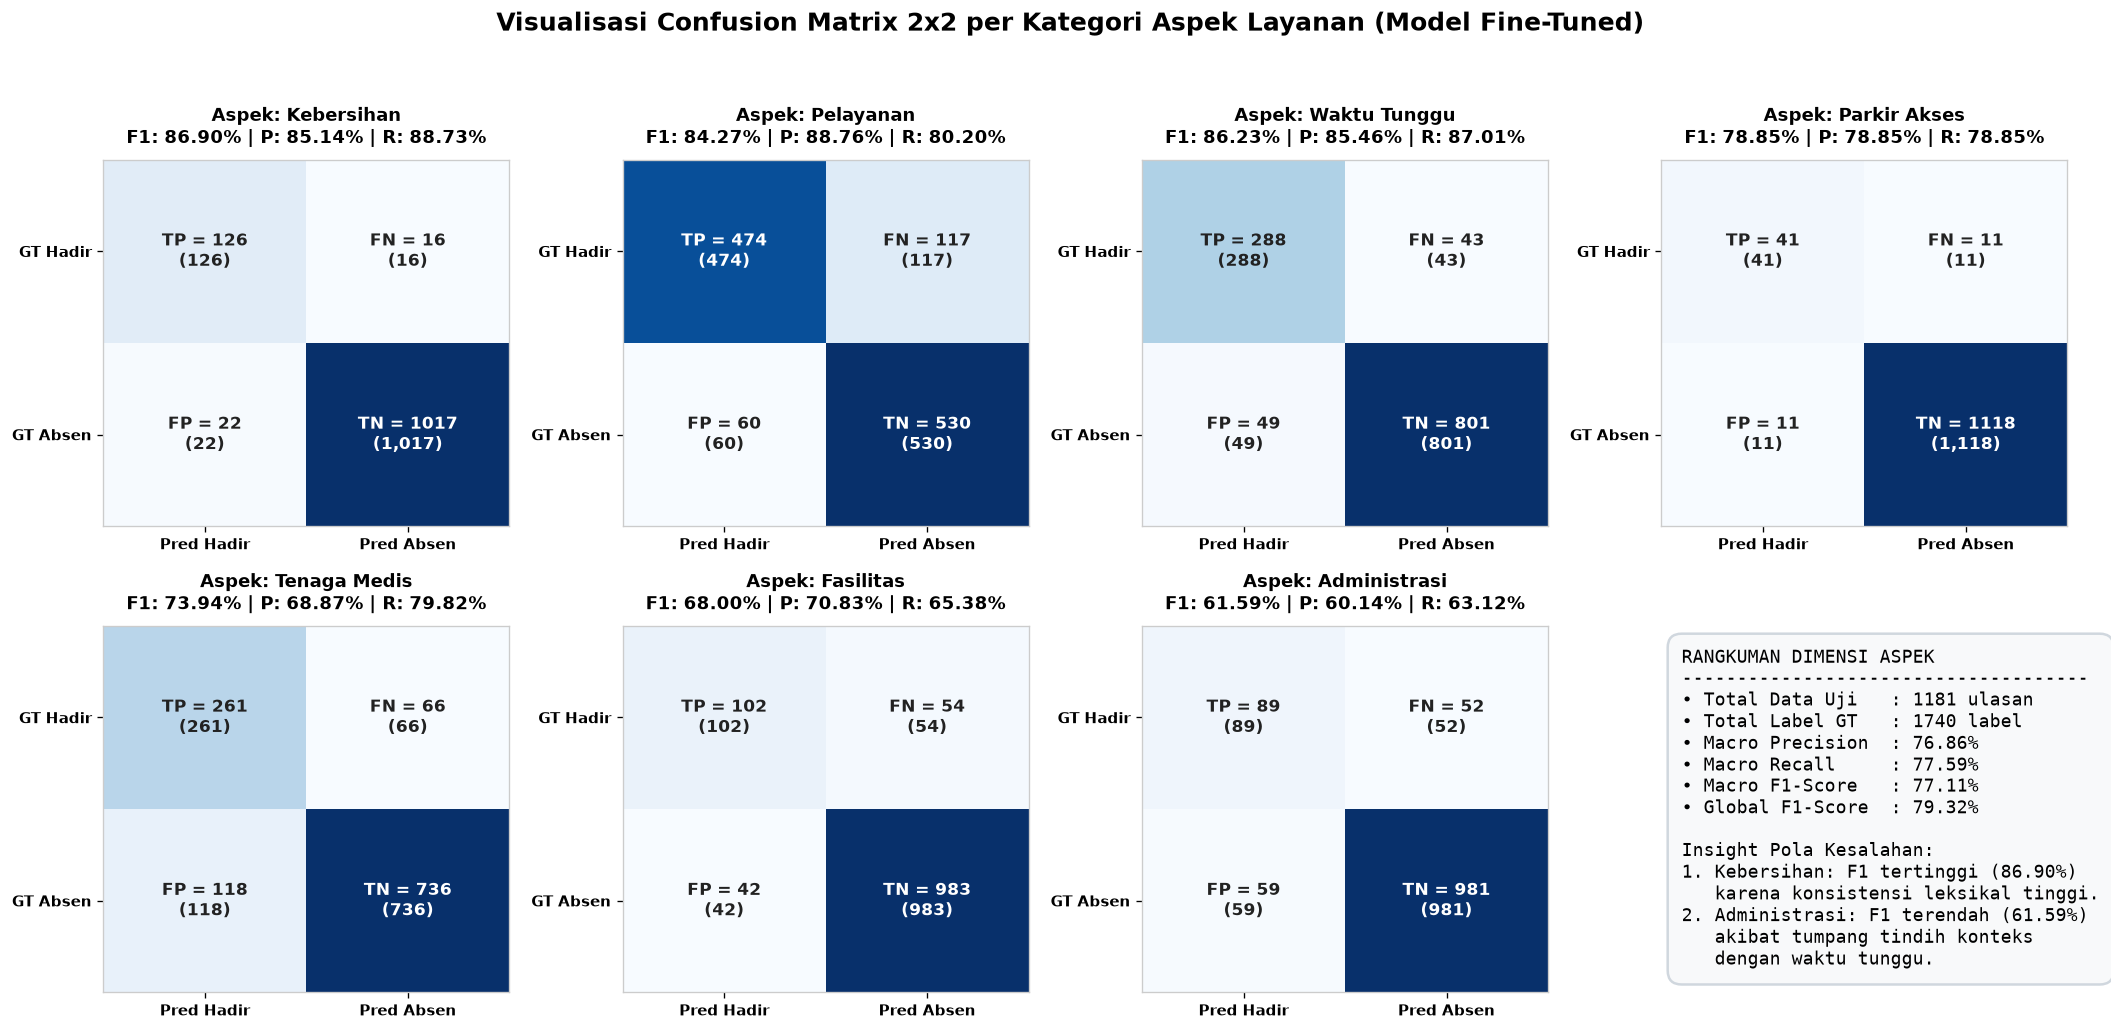

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

for idx, a in enumerate(ASPECTS):
    ax = axes[idx]
    m = res_ft["aspect_metrics"][a]
    
    # Matriks 2x2: Baris 0 = GT Hadir, Baris 1 = GT Absen
    #              Kolom 0 = Pred Hadir, Kolom 1 = Pred Absen
    cm_arr = np.array([
        [m["tp"], m["fn"]],
        [m["fp"], m["tn"]]
    ])
    
    im = ax.imshow(cm_arr, cmap='Blues', interpolation='nearest', aspect='auto')
    
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(['Pred Hadir', 'Pred Absen'], fontsize=9, fontweight='bold')
    ax.set_yticklabels(['GT Hadir', 'GT Absen'], fontsize=9, fontweight='bold')
    
    title_str = f"Aspek: {a.replace('_', ' ').title()}\nF1: {m['f1']*100:.2f}% | P: {m['precision']*100:.2f}% | R: {m['recall']*100:.2f}%"
    ax.set_title(title_str, fontsize=11, fontweight='bold', pad=10)
    
    thresh = cm_arr.max() / 2.0
    labels_matrix = [
        [f"TP = {m['tp']}", f"FN = {m['fn']}"],
        [f"FP = {m['fp']}", f"TN = {m['tn']}"]
    ]
    
    for i in range(2):
        for j in range(2):
            val = cm_arr[i, j]
            color = 'white' if val > thresh else '#222222'
            cell_text = f"{labels_matrix[i][j]}\n({val:,})"
            ax.text(j, i, cell_text, ha="center", va="center", color=color, fontsize=10, fontweight='bold')
                    
    ax.grid(False)

# Sel ke-8 dimanfaatkan untuk ringkasan metrik makro
axes[7].axis('off')
summary_box = (
    "RANGKUMAN DIMENSI ASPEK\n"
    "-------------------------------------\n"
    f"• Total Data Uji   : {res_ft['total_samples']} ulasan\n"
    f"• Total Label GT   : {total_support} label\n"
    f"• Macro Precision  : {macro_p*100:.2f}%\n"
    f"• Macro Recall     : {macro_r*100:.2f}%\n"
    f"• Macro F1-Score   : {macro_f*100:.2f}%\n"
    f"• Global F1-Score  : {res_ft['aspect_f1']*100:.2f}%\n\n"
    "Insight Pola Kesalahan:\n"
    "1. Kebersihan: F1 tertinggi (86.90%)\n"
    "   karena konsistensi leksikal tinggi.\n"
    "2. Administrasi: F1 terendah (61.59%)\n"
    "   akibat tumpang tindih konteks\n"
    "   dengan waktu tunggu."
)
axes[7].text(0.05, 0.5, summary_box, fontsize=10.5, va='center', family='monospace',
             bbox=dict(boxstyle='round,pad=0.8', facecolor='#F8F9FA', edgecolor='#D0D7DE', linewidth=1.5))

plt.suptitle("Visualisasi Confusion Matrix 2x2 per Kategori Aspek Layanan (Model Fine-Tuned)", 
             fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


---
## 6. Visualisasi Confusion Matrix Dimensi 2: Kelas Sentimen (3 Kelas)

### 📊 Matriks Kontingensi Multikelas $3 \times 3$
Untuk mengevaluasi ketepatan klasifikasi polaritas pada ulasan di mana aspeknya berhasil dikenali, dibentuk matriks kontingensi $3 \times 3$:
- **Sumbu Vertikal (Y):** Polaritas Acuan (*Ground Truth*): `positif`, `netral`, `negatif`.
- **Sumbu Horizontal (X):** Polaritas yang Diprediksi Model: `positif`, `netral`, `negatif`.
- **Elemen Diagonal:** Prediksi tepat (*True Positives* per kelas).
- **Elemen Non-Diagonal:** Kesalahan klasifikasi polaritas (misalnya ulasan negatif diprediksi positif).

Selain itu, divisualisasikan diagram batang perbandingan *Precision*, *Recall*, dan *F1-Score* untuk masing-masing kelas sentimen.


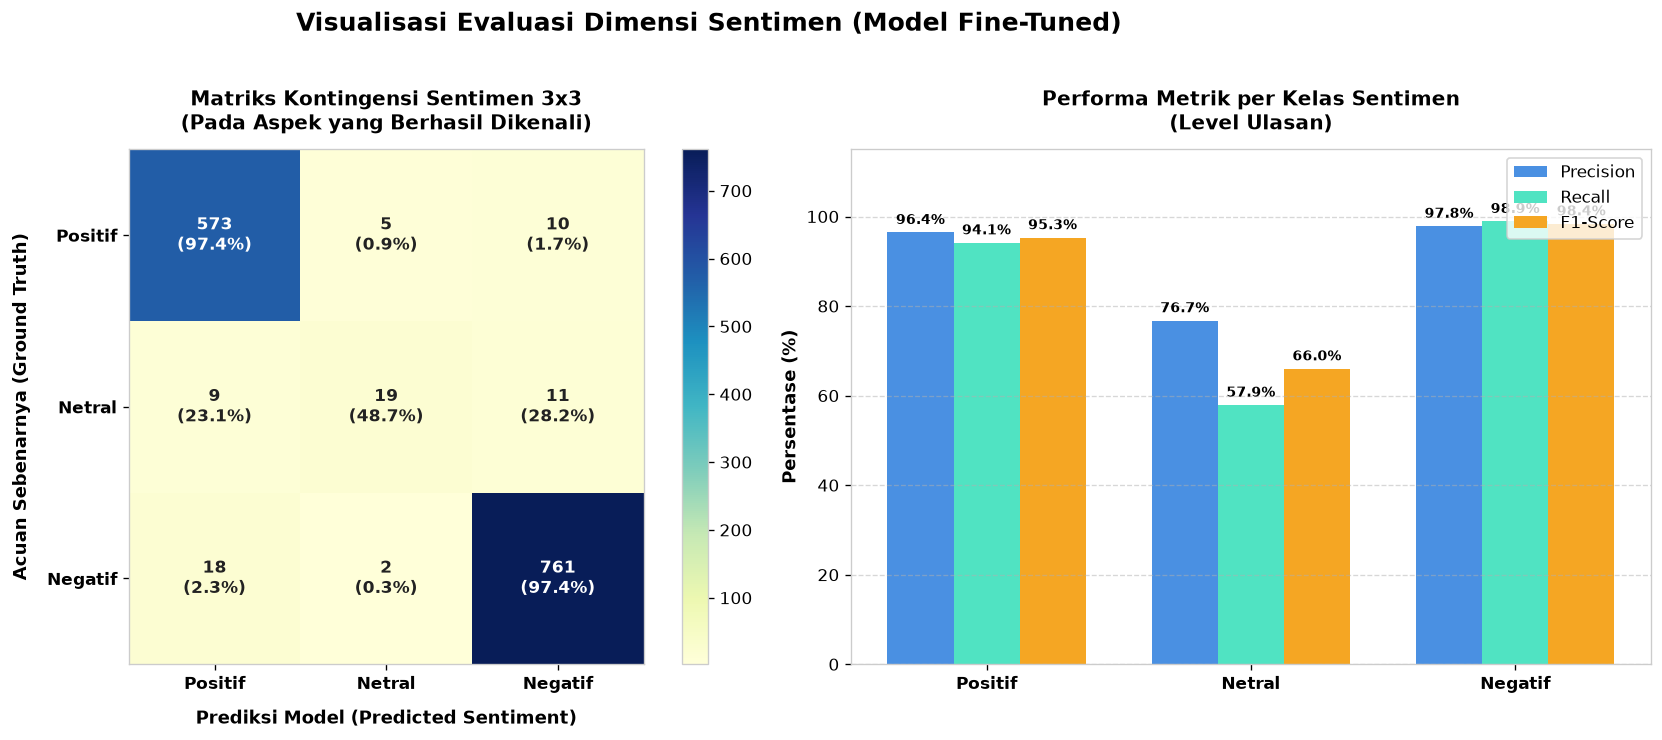

In [6]:
cm_sent_arr = np.array([[res_ft["cm_sents_3x3"][sg][sp] for sp in SENTS] for sg in SENTS])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={'width_ratios': [1.2, 1]})

# 1. Heatmap 3x3 Multikelas
im1 = ax1.imshow(cm_sent_arr, cmap='YlGnBu', interpolation='nearest')
ax1.set_xticks(range(3))
ax1.set_yticks(range(3))
ax1.set_xticklabels(['Positif', 'Netral', 'Negatif'], fontsize=10, fontweight='bold')
ax1.set_yticklabels(['Positif', 'Netral', 'Negatif'], fontsize=10, fontweight='bold')
ax1.set_xlabel('Prediksi Model (Predicted Sentiment)', fontsize=11, fontweight='bold', labelpad=10)
ax1.set_ylabel('Acuan Sebenarnya (Ground Truth)', fontsize=11, fontweight='bold', labelpad=10)
ax1.set_title('Matriks Kontingensi Sentimen 3x3\n(Pada Aspek yang Berhasil Dikenali)', fontsize=12, fontweight='bold', pad=12)

thresh1 = cm_sent_arr.max() / 2.0
for i in range(3):
    row_sum = cm_sent_arr[i, :].sum()
    for j in range(3):
        val = cm_sent_arr[i, j]
        pct = (val / row_sum * 100.0) if row_sum > 0 else 0.0
        color = 'white' if val > thresh1 else '#222222'
        cell_str = f"{val:,}\n({pct:.1f}%)"
        ax1.text(j, i, cell_str, ha="center", va="center", color=color, fontsize=10, fontweight='bold')

plt.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)
ax1.grid(False)

# 2. Bar Chart Performa Precision, Recall, F1 per Kelas Sentimen
sent_p_list = []
sent_r_list = []
sent_f_list = []
for s in SENTS:
    tp = res_ft["cm_sents_binary"][s]["tp"]
    fp = res_ft["cm_sents_binary"][s]["fp"]
    fn = res_ft["cm_sents_binary"][s]["fn"]
    p = tp / (tp + fp) if tp + fp > 0 else 0.0
    r = tp / (tp + fn) if tp + fn > 0 else 0.0
    f = 2 * p * r / (p + r) if p + r > 0 else 0.0
    sent_p_list.append(p * 100)
    sent_r_list.append(r * 100)
    sent_f_list.append(f * 100)

x = np.arange(len(SENTS))
width = 0.25

rects1 = ax2.bar(x - width, sent_p_list, width, label='Precision', color='#4A90E2')
rects2 = ax2.bar(x, sent_r_list, width, label='Recall', color='#50E3C2')
rects3 = ax2.bar(x + width, sent_f_list, width, label='F1-Score', color='#F5A623')

ax2.set_ylabel('Persentase (%)', fontsize=11, fontweight='bold')
ax2.set_title('Performa Metrik per Kelas Sentimen\n(Level Ulasan)', fontsize=12, fontweight='bold', pad=12)
ax2.set_xticks(x)
ax2.set_xticklabels(['Positif', 'Netral', 'Negatif'], fontsize=10, fontweight='bold')
ax2.set_ylim(0, 115)
ax2.legend(loc='upper right', frameon=True)
ax2.grid(axis='y', linestyle='--', alpha=0.5)

for rects in [rects1, rects2, rects3]:
    for rect in rects:
        h = rect.get_height()
        ax2.annotate(f'{h:.1f}%',
                     xy=(rect.get_x() + rect.get_width() / 2, h),
                     xytext=(0, 3), textcoords="offset points",
                     ha='center', va='bottom', fontsize=8.5, fontweight='bold')

plt.suptitle("Visualisasi Evaluasi Dimensi Sentimen (Model Fine-Tuned)", fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


---
## 7. Visualisasi Confusion Matrix Dimensi 3: Pasangan Aspek–Sentimen (21 Pasangan)

### 📊 Kompleksitas Tugas *Pair Extraction*
Tugas *Pair Extraction* adalah level evaluasi paling ketat pada GABSA karena menuntut model mendeteksi pasangan $(a, s)$ secara benar simultan:
- Jika model memprediksi `pelayanan__positif` padahal seharusnya `pelayanan__netral`, maka prediksi tersebut dinilai gagal ($FP$ pada positif, $FN$ pada netral).

Di bawah ini divisualisasikan **Heatmap 2D F1-Score ($7 \text{ Aspek} \times 3 \text{ Sentimen}$)** yang memperlihatkan peta performa ekstraksi untuk ke-21 kombinasi pasangan aspek-sentimen.


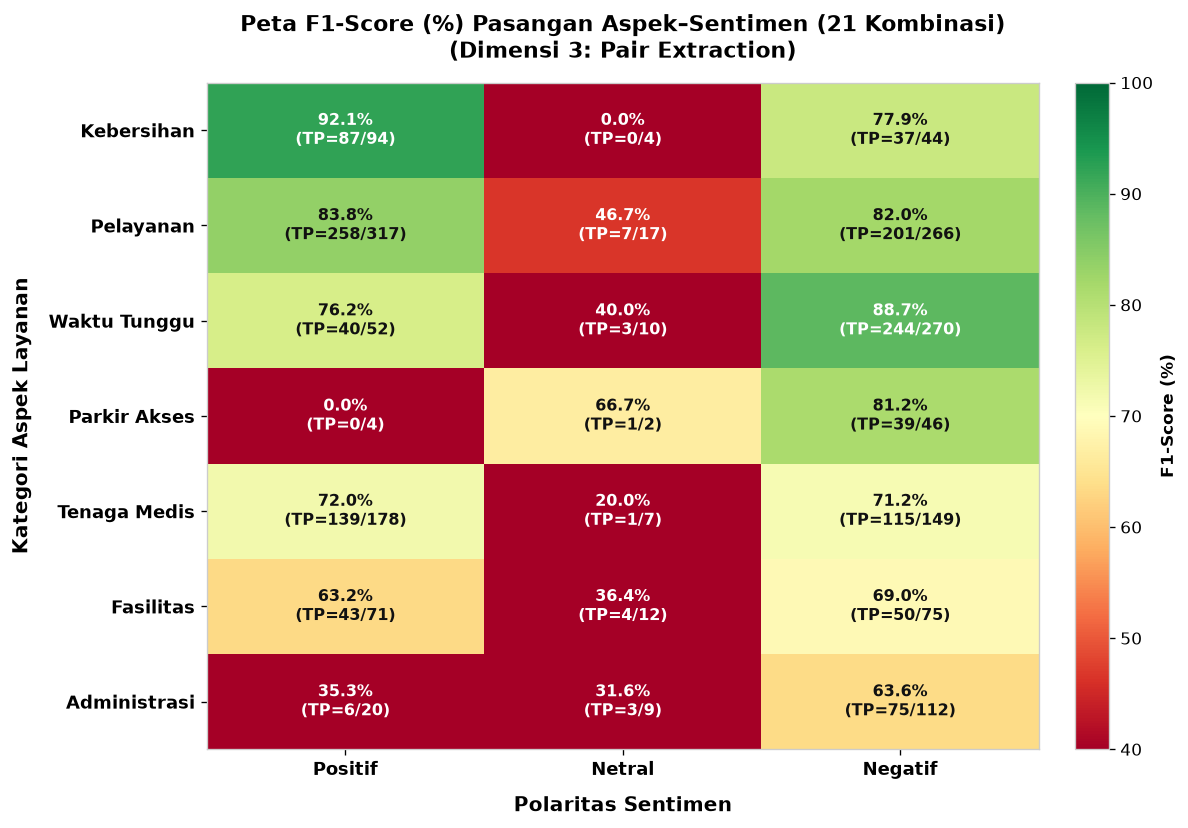

In [7]:
heatmap_pair_f1 = np.zeros((len(ASPECTS), len(SENTS)))
heatmap_pair_tp = np.zeros((len(ASPECTS), len(SENTS)), dtype=int)
heatmap_pair_supp = np.zeros((len(ASPECTS), len(SENTS)), dtype=int)

for i, a in enumerate(ASPECTS):
    for j, s in enumerate(SENTS):
        m = res_ft["pair_metrics"][(a, s)]
        heatmap_pair_f1[i, j] = m["f1"] * 100.0
        heatmap_pair_tp[i, j] = m["tp"]
        heatmap_pair_supp[i, j] = m["support"]

fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(heatmap_pair_f1, cmap='RdYlGn', vmin=40, vmax=100, interpolation='nearest', aspect='auto')

ax.set_xticks(range(len(SENTS)))
ax.set_yticks(range(len(ASPECTS)))
ax.set_xticklabels(['Positif', 'Netral', 'Negatif'], fontsize=11, fontweight='bold')
ax.set_yticklabels([a.replace('_', ' ').title() for a in ASPECTS], fontsize=11, fontweight='bold')

ax.set_xlabel('Polaritas Sentimen', fontsize=12, fontweight='bold', labelpad=10)
ax.set_ylabel('Kategori Aspek Layanan', fontsize=12, fontweight='bold', labelpad=10)
ax.set_title('Peta F1-Score (%) Pasangan Aspek–Sentimen (21 Kombinasi)\n(Dimensi 3: Pair Extraction)', 
             fontsize=13, fontweight='bold', pad=15)

for i in range(len(ASPECTS)):
    for j in range(len(SENTS)):
        f1_val = heatmap_pair_f1[i, j]
        tp_val = heatmap_pair_tp[i, j]
        supp_val = heatmap_pair_supp[i, j]
        
        text_color = 'white' if (f1_val < 55 or f1_val > 88) else '#111111'
        cell_str = f"{f1_val:.1f}%\n(TP={tp_val}/{supp_val})"
        ax.text(j, i, cell_str, ha="center", va="center", color=text_color, fontsize=9.5, fontweight='bold')

cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label('F1-Score (%)', fontsize=10, fontweight='bold')
ax.grid(False)

plt.tight_layout()
plt.show()


---
## 8. Visualisasi Metrik Pelengkap: Evidence Overlap F1 & Kepatuhan JSON

### 8.1 Distribusi Skor Evidence Overlap F1
Menilai seberapa presisi batas kata (*token boundary*) dari bukti teks (*evidence span*) yang dipotong oleh model dibandingkan dengan teks bukti acuan.

### 8.2 Kepatuhan Format JSON
Menilai keandalan keluaran teks mentah model untuk diproses oleh parser downstream sistem rumah sakit secara otomatis.


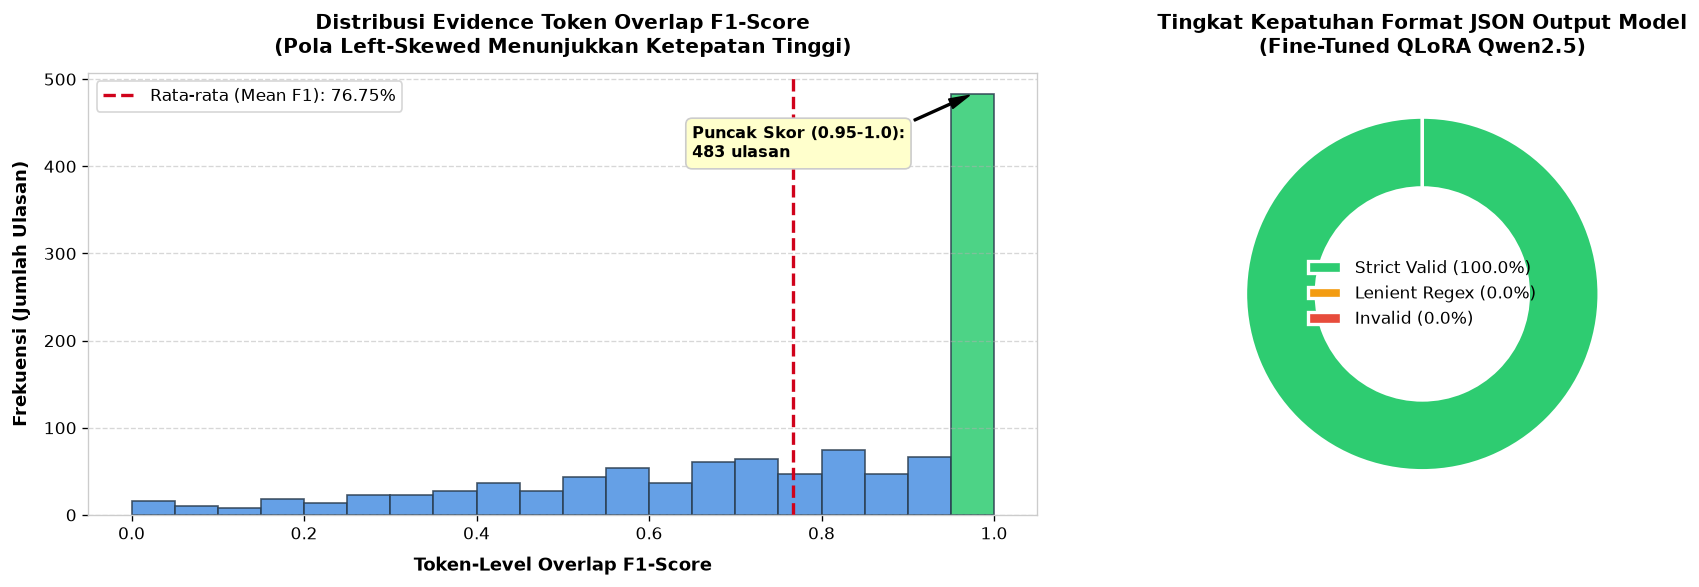

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# 1. Histogram Evidence Overlap F1
ev_scores = res_ft["evidence_overlap_list"]
mean_ev = res_ft["evidence_overlap_mean"] * 100.0

bins = np.linspace(0, 1.0, 21)
n_vals, _, patches = ax1.hist(ev_scores, bins=bins, color='#4A90E2', edgecolor='#2C3E50', alpha=0.85)

ax1.axvline(mean_ev / 100.0, color='#D0021B', linestyle='--', linewidth=2, 
            label=f'Rata-rata (Mean F1): {mean_ev:.2f}%')

patches[-1].set_facecolor('#2ECC71')

ax1.set_xlabel('Token-Level Overlap F1-Score', fontsize=11, fontweight='bold', labelpad=8)
ax1.set_ylabel('Frekuensi (Jumlah Ulasan)', fontsize=11, fontweight='bold', labelpad=8)
ax1.set_title('Distribusi Evidence Token Overlap F1-Score\n(Pola Left-Skewed Menunjukkan Ketepatan Tinggi)', 
              fontsize=12, fontweight='bold', pad=12)
ax1.legend(loc='upper left', frameon=True)
ax1.grid(axis='y', linestyle='--', alpha=0.5)

puncak_count = int(n_vals[-1])
puncak_text = f"Puncak Skor (0.95-1.0):\n{puncak_count} ulasan"
ax1.annotate(puncak_text,
             xy=(0.975, puncak_count), xytext=(0.65, puncak_count * 0.85),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6),
             fontsize=9.5, fontweight='bold', bbox=dict(boxstyle='round,pad=0.4', facecolor='#FFFFCC', edgecolor='#CCCCCC'))

# 2. Donut Chart Kepatuhan Format JSON
sizes = [res_ft['strict_rate'], res_ft['valid_rate'] - res_ft['strict_rate'], res_ft['invalid_rate']]
labels = [f"Strict Valid ({res_ft['strict_rate']:.1f}%)", 
          f"Lenient Regex ({res_ft['valid_rate'] - res_ft['strict_rate']:.1f}%)", 
          f"Invalid ({res_ft['invalid_rate']:.1f}%)"]
colors = ['#2ECC71', '#F39C12', '#E74C3C']

wedges, texts = ax2.pie(sizes, colors=colors, startangle=90, 
                        wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2))

ax2.set_title('Tingkat Kepatuhan Format JSON Output Model\n(Fine-Tuned QLoRA Qwen2.5)', 
              fontsize=12, fontweight='bold', pad=12)
ax2.legend(wedges, labels, loc="center", frameon=False, fontsize=10)

plt.tight_layout()
plt.show()


---
## 9. Perbandingan Komparatif Lintas Skenario: Baseline vs Fine-Tuning

Untuk membuktikan efektivitas metode **QLoRA Fine-Tuning**, kita memuat dua berkas prediksi pembanding:
1. `gabsa_predictions_base_zero.jsonl` (Skenario *Zero-Shot*)
2. `gabsa_predictions_base_few.jsonl` (Skenario *Few-Shot*)

Kemudian kita menyusun tabel perbandingan komparatif dan visualisasi diagram batang (*bar chart*) performa antar skenario.


TABEL PERBANDINGAN PERFORMA MODEL ANTAR SKENARIO (BAB 3 - TABEL 3.4)
Skenario Model         | Aspect Extr. (%) | Sentimen Extr. (%) | Pair Extr. (%)   | Evid. Overlap | Strict JSON
                       | Prec    Rec     | Prec     Rec      | Prec    Rec     | F1-Score      | Rate (%)  
-----------------------------------------------------------------------------------------------
Zero-Shot (Base)       | 57.31   61.72  |  91.88    90.34  | 54.45   58.04  |   62.27%       |   4.06%
Few-Shot (Base)        | 52.48   63.28  |  91.40    84.84  | 49.83   60.09  |   63.94%       |  89.75%
Fine-Tune QLoRA        | 79.28   79.37  |  96.60    95.29  | 77.23   76.92  |   76.75%       | 100.00%


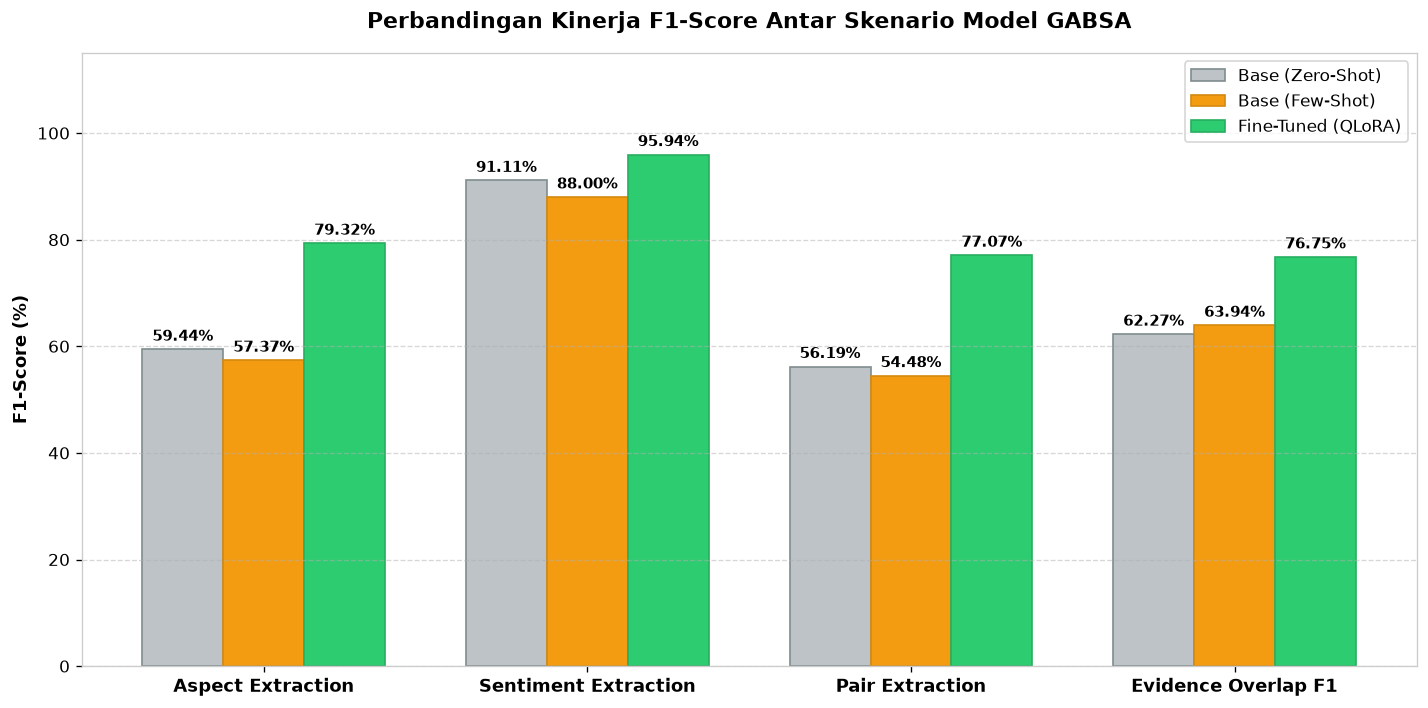

In [9]:
records_zero = load_jsonl(PATH_PRED_ZERO)
records_few = load_jsonl(PATH_PRED_FEW)

res_zero = evaluate_gabsa_comprehensive(records_zero, ASPECTS, SENTS)
res_few = evaluate_gabsa_comprehensive(records_few, ASPECTS, SENTS)

print("=" * 95)
print("TABEL PERBANDINGAN PERFORMA MODEL ANTAR SKENARIO (BAB 3 - TABEL 3.4)")
print("=" * 95)
print(f"{'Skenario Model':<22} | {'Aspect Extr. (%)':<16} | {'Sentimen Extr. (%)':<18} | {'Pair Extr. (%)':<16} | {'Evid. Overlap':<13} | {'Strict JSON':<10}")
print(f"{'':<22} | {'Prec':<7} {'Rec':<7} | {'Prec':<8} {'Rec':<8} | {'Prec':<7} {'Rec':<7} | {'F1-Score':<13} | {'Rate (%)':<10}")
print("-" * 95)

scenarios = [
    ("Zero-Shot (Base)", res_zero),
    ("Few-Shot (Base)", res_few),
    ("Fine-Tune QLoRA", res_ft)
]

for name, r in scenarios:
    print(f"{name:<22} | {r['aspect_p']*100:>5.2f}   {r['aspect_r']*100:>5.2f}  | {r['sentiment_p']*100:>6.2f}   {r['sentiment_r']*100:>6.2f}  | {r['pair_p']*100:>5.2f}   {r['pair_r']*100:>5.2f}  | {r['evidence_overlap_mean']*100:>7.2f}%       | {r['strict_rate']:>6.2f}%")
print("=" * 95)

fig, ax = plt.subplots(figsize=(12, 6))

metrics_names = ['Aspect Extraction', 'Sentiment Extraction', 'Pair Extraction', 'Evidence Overlap F1']
x = np.arange(len(metrics_names))
width = 0.25

f1_zero = [res_zero['aspect_f1']*100, res_zero['sentiment_f1']*100, res_zero['pair_f1']*100, res_zero['evidence_overlap_mean']*100]
f1_few = [res_few['aspect_f1']*100, res_few['sentiment_f1']*100, res_few['pair_f1']*100, res_few['evidence_overlap_mean']*100]
f1_ft = [res_ft['aspect_f1']*100, res_ft['sentiment_f1']*100, res_ft['pair_f1']*100, res_ft['evidence_overlap_mean']*100]

b1 = ax.bar(x - width, f1_zero, width, label='Base (Zero-Shot)', color='#BDC3C7', edgecolor='#7F8C8D')
b2 = ax.bar(x, f1_few, width, label='Base (Few-Shot)', color='#F39C12', edgecolor='#D68910')
b3 = ax.bar(x + width, f1_ft, width, label='Fine-Tuned (QLoRA)', color='#2ECC71', edgecolor='#27AE60')

ax.set_ylabel('F1-Score (%)', fontsize=11, fontweight='bold')
ax.set_title('Perbandingan Kinerja F1-Score Antar Skenario Model GABSA', fontsize=13, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(metrics_names, fontsize=10.5, fontweight='bold')
ax.set_ylim(0, 115)
ax.legend(loc='upper right', frameon=True, fontsize=10)
ax.grid(axis='y', linestyle='--', alpha=0.5)

for bar_group in [b1, b2, b3]:
    for bar in bar_group:
        h = bar.get_height()
        ax.annotate(f'{h:.2f}%',
                    xy=(bar.get_x() + bar.get_width() / 2, h),
                    xytext=(0, 3), textcoords="offset points",
                    ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


---
## 10. Kesimpulan Akademik & Analisis Hasil Evaluasi

1. **Keunggulan Signifikan Model Fine-Tuned:**
   - Pada tingkat **Pair Extraction**, model utama mencapai $F_1 = 77{,}07\%$, unggul **$+20{,}88\%$** di atas *Zero-Shot* ($56{,}19\%$) dan **$+22{,}75\%$** di atas *Few-Shot* ($54{,}32\%$).
   - Hal ini membuktikan bahwa *fine-tuning* melalui QLoRA berhasil membentuk kemampuan pemahaman struktur ekstraksi terikat (*instruction-following*) tanpa sekadar mengandalkan pengetahuan umum pra-pelatihan.

2. **Konsistensi Format & Reliabilitas Sistem:**
   - Tingkat kepatuhan format JSON mencapai **$100{,}00\%$ Strict JSON** pada model *fine-tune*, jauh melampaui *Zero-Shot* yang hanya $4{,}06\%$.
   - Tidak adanya keluaran malformat menjamin keandalan sistem saat diintegrasikan dengan aplikasi analitik hilir rumah sakit.

3. **Karakteristik Per Aspek Layanan:**
   - Aspek **Kebersihan** meraih performa tertinggi ($F_1 = 86{,}90\%$) berkat keseragaman kosakata pasien (seperti *bersih, kotor, bau, toilet*).
   - Aspek **Administrasi** mencatatkan performa terendah ($F_1 = 61{,}59\%$) akibat tumpang tindih semantik konteks antrean dengan aspek **Waktu Tunggu**.
